BAGIAN 1 — Setup Colab

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install ultralytics -q

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 6.8 MB/s eta 0:00:00


In [2]:
import os
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

from ultralytics import YOLO

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
MODEL_PATH = "/content/drive/MyDrive/LettuceCare_best.pt"

DATASET_PATH = "/content/drive/MyDrive/LettuceCare_Dataset_2000"
TEST_PATH = os.path.join(DATASET_PATH, "test")

RESULT_PATH = "/content/drive/MyDrive/LettuceCare_Evaluation"

os.makedirs(RESULT_PATH, exist_ok=True)

print("Model :", MODEL_PATH)
print("Test  :", TEST_PATH)
print("Hasil :", RESULT_PATH)

Model : /content/drive/MyDrive/LettuceCare_best.pt
Test  : /content/drive/MyDrive/LettuceCare_Dataset_2000/test
Hasil : /content/drive/MyDrive/LettuceCare_Evaluation


In [4]:
print("Model tersedia :", os.path.exists(MODEL_PATH))
print("Dataset test   :", os.path.exists(TEST_PATH))

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        "LettuceCare_best.pt tidak ditemukan di Google Drive."
    )

if not os.path.exists(TEST_PATH):
    raise FileNotFoundError(
        "Folder dataset test tidak ditemukan."
    )

Model tersedia : True
Dataset test   : True


BAGIAN 2 — Load best.pt

In [5]:
model = YOLO(MODEL_PATH)

device = 0 if torch.cuda.is_available() else "cpu"

print("Device:", "GPU" if torch.cuda.is_available() else "CPU")
print("Nama kelas model:")
print(model.names)

Device: CPU
Nama kelas model:
{0: 'Bacterial', 1: 'Powdery_mildew_on_lettuce', 2: 'Wilt_and_leaf_blight_on_lettuce', 3: 'fungal', 4: 'healthy'}


In [6]:
classes = [
    "Bacterial",
    "Powdery_mildew_on_lettuce",
    "Wilt_and_leaf_blight_on_lettuce",
    "fungal",
    "healthy"
]

print("Kelas evaluasi:")

for i, cls in enumerate(classes):
    print(i, cls)

Kelas evaluasi:
0 Bacterial
1 Powdery_mildew_on_lettuce
2 Wilt_and_leaf_blight_on_lettuce
3 fungal
4 healthy


In [7]:
total_test = 0

for cls in classes:

    class_path = os.path.join(TEST_PATH, cls)

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print(f"{cls}: {len(images)} gambar")

    total_test += len(images)

print("\nTotal data test:", total_test)

Bacterial: 20 gambar
Powdery_mildew_on_lettuce: 20 gambar
Wilt_and_leaf_blight_on_lettuce: 20 gambar
fungal: 20 gambar
healthy: 20 gambar

Total data test: 100


In [8]:
test_data = []

extensions = (".jpg", ".jpeg", ".png")

for true_class in classes:

    class_folder = Path(TEST_PATH) / true_class

    for image_path in sorted(class_folder.iterdir()):

        if image_path.suffix.lower() in extensions:

            test_data.append({
                "image_path": str(image_path),
                "true_label": true_class
            })

print("Jumlah gambar yang akan dievaluasi:", len(test_data))

Jumlah gambar yang akan dievaluasi: 100


In [9]:
image_paths = [
    item["image_path"]
    for item in test_data
]

results = model.predict(
    source=image_paths,
    imgsz=224,
    device=device,
    verbose=False
)

evaluation_results = []

for item, result in zip(test_data, results):

    predicted_id = int(result.probs.top1)

    predicted_class = result.names[predicted_id]

    confidence = float(
        result.probs.top1conf.cpu().item()
    )

    evaluation_results.append({
        "image": os.path.basename(item["image_path"]),
        "true_label": item["true_label"],
        "predicted_label": predicted_class,
        "confidence": confidence,
        "correct": item["true_label"] == predicted_class
    })

df_test = pd.DataFrame(evaluation_results)

df_test.head()

,image,true_label,predicted_label,confidence,correct
0,11100_jpg.rf.30f5afac4837213ff292ebdaed8dafe7.jpg,Bacterial,Bacterial,0.997392,True
1,11101_jpg.rf.f4c696e476bf2affdf0be53eacca98a3.jpg,Bacterial,Bacterial,0.999963,True
2,11104_jpg.rf.a49f4fe96bde659a5f2098449ca96518.jpg,Bacterial,Bacterial,0.767413,True
3,augmented_10_jpg.rf.518cdc57c0eb54790ee9834ad6...,Bacterial,Wilt_and_leaf_blight_on_lettuce,0.850497,False
4,augmented_1_jpg.rf.cb7704ce2e1f205123dd585e9d5...,Bacterial,Bacterial,0.972206,True


In [10]:
display(
    df_test[
        [
            "image",
            "true_label",
            "predicted_label",
            "confidence",
            "correct"
        ]
    ]
)

,image,true_label,predicted_label,confidence,correct
0,11100_jpg.rf.30f5afac4837213ff292ebdaed8dafe7.jpg,Bacterial,Bacterial,0.997392,True
1,11101_jpg.rf.f4c696e476bf2affdf0be53eacca98a3.jpg,Bacterial,Bacterial,0.999963,True
2,11104_jpg.rf.a49f4fe96bde659a5f2098449ca96518.jpg,Bacterial,Bacterial,0.767413,True
3,augmented_10_jpg.rf.518cdc57c0eb54790ee9834ad6...,Bacterial,Wilt_and_leaf_blight_on_lettuce,0.850497,False
4,augmented_1_jpg.rf.cb7704ce2e1f205123dd585e9d5...,Bacterial,Bacterial,0.972206,True
...,...,...,...,...,...
95,images-1-_jpg.rf.07b7578493c7a21ec317646175e60...,healthy,healthy,0.992991,True
96,images-4-_jpg.rf.6d0ece65cb6d18b41f43be0a0da97...,healthy,healthy,0.999997,True
97,images-6-_jpg.rf.3a880646a9a90e3ad9b4bf0a2b5b9...,healthy,healthy,0.999731,True
98,images_jpg.rf.37ff433c4c078298a9216df49fef76f6...,healthy,healthy,0.999320,True


In [11]:
y_true = df_test["true_label"]
y_pred = df_test["predicted_label"]

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=classes,
    average="macro",
    zero_division=0
)

average_confidence = df_test["confidence"].mean()

print("===== HASIL EVALUASI TEST =====")

print(f"Accuracy           : {accuracy * 100:.2f}%")
print(f"Precision (Macro)  : {precision * 100:.2f}%")
print(f"Recall (Macro)     : {recall * 100:.2f}%")
print(f"F1-Score (Macro)   : {f1 * 100:.2f}%")
print(f"Average Confidence : {average_confidence * 100:.2f}%")

===== HASIL EVALUASI TEST =====
Accuracy           : 92.00%
Precision (Macro)  : 92.53%
Recall (Macro)     : 92.00%
F1-Score (Macro)   : 91.95%
Average Confidence : 96.15%


In [12]:
report = classification_report(
    y_true,
    y_pred,
    labels=classes,
    target_names=classes,
    output_dict=True,
    zero_division=0
)

df_report = pd.DataFrame(report).transpose()

display(df_report)

,precision,recall,f1-score,support
Bacterial,0.791667,0.95,0.863636,20.00
Powdery_mildew_on_lettuce,1.000000,0.90,0.947368,20.00
Wilt_and_leaf_blight_on_lettuce,0.952381,1.00,0.975610,20.00
fungal,0.882353,0.75,0.810811,20.00
healthy,1.000000,1.00,1.000000,20.00
accuracy,0.920000,0.92,0.920000,0.92
macro avg,0.925280,0.92,0.919485,100.00
weighted avg,0.925280,0.92,0.919485,100.00


In [13]:
report_file = os.path.join(
    RESULT_PATH,
    "classification_report_test.csv"
)

df_report.to_csv(report_file)

print("Classification report disimpan:")
print(report_file)

Classification report disimpan:
/content/drive/MyDrive/LettuceCare_Evaluation/classification_report_test.csv


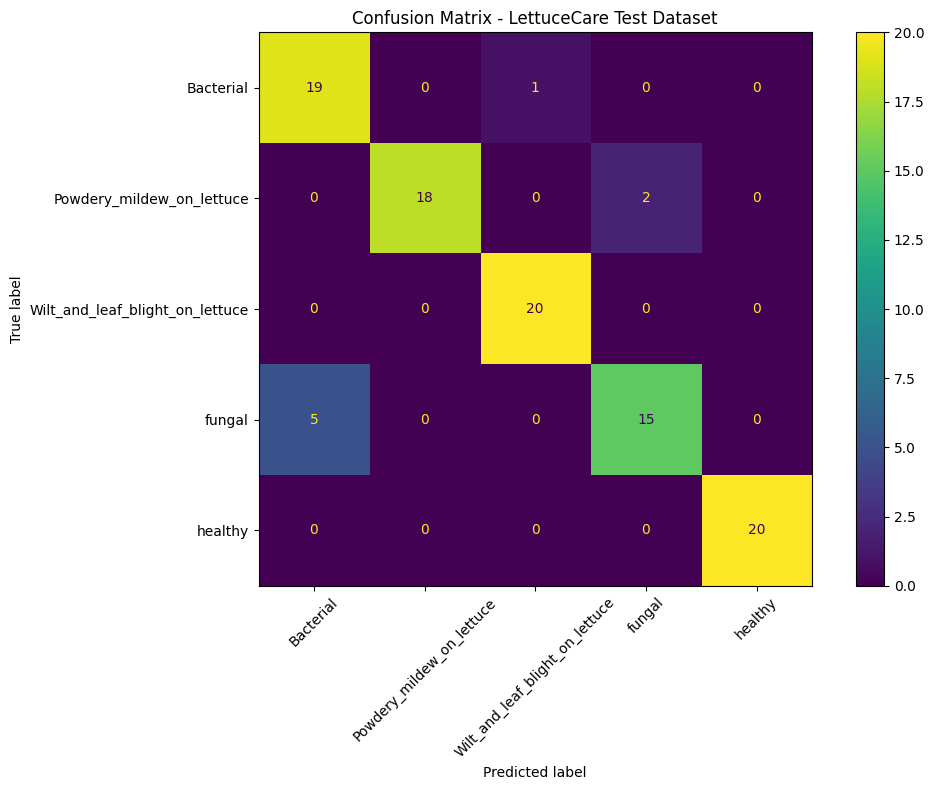

Confusion matrix disimpan:
/content/drive/MyDrive/LettuceCare_Evaluation/confusion_matrix_test.png


In [14]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=classes
)

fig, ax = plt.subplots(figsize=(11, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)

plt.title(
    "Confusion Matrix - LettuceCare Test Dataset"
)

plt.tight_layout()

confusion_file = os.path.join(
    RESULT_PATH,
    "confusion_matrix_test.png"
)

plt.savefig(
    confusion_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix disimpan:")
print(confusion_file)

In [15]:
prediction_file = os.path.join(
    RESULT_PATH,
    "test_predictions.csv"
)

df_test.to_csv(
    prediction_file,
    index=False
)

print("Data prediksi disimpan:")
print(prediction_file)

Data prediksi disimpan:
/content/drive/MyDrive/LettuceCare_Evaluation/test_predictions.csv


In [16]:
summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1-Score Macro",
        "Average Confidence"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        average_confidence
    ]
})

display(summary)

summary.to_csv(
    os.path.join(
        RESULT_PATH,
        "test_metrics.csv"
    ),
    index=False
)

,Metric,Value
0,Accuracy,0.920000
1,Precision Macro,0.925280
2,Recall Macro,0.920000
3,F1-Score Macro,0.919485
4,Average Confidence,0.961549


In [17]:
import os

REAL_TEST_PATH = "/content/drive/MyDrive/LettuceCare_RealTest"

classes = [
    "Bacterial",
    "Powdery_mildew_on_lettuce",
    "Wilt_and_leaf_blight_on_lettuce",
    "fungal",
    "healthy"
]

os.makedirs(REAL_TEST_PATH, exist_ok=True)

for cls in classes:
    os.makedirs(
        os.path.join(REAL_TEST_PATH, cls),
        exist_ok=True
    )

print("Folder Real Test berhasil dibuat.")

Folder Real Test berhasil dibuat.


In [18]:
from pathlib import Path

extensions = (".jpg", ".jpeg", ".png")

total = 0

for cls in classes:

    folder = Path(REAL_TEST_PATH) / cls

    images = [
        img for img in folder.iterdir()
        if img.suffix.lower() in extensions
    ]

    print(f"{cls}: {len(images)} gambar")

    total += len(images)

print("\nTotal gambar Real Test:", total)

Bacterial: 2 gambar
Powdery_mildew_on_lettuce: 2 gambar
Wilt_and_leaf_blight_on_lettuce: 2 gambar
fungal: 2 gambar
healthy: 3 gambar

Total gambar Real Test: 11


In [21]:
real_test_data = []
extensions = (".jpg", ".jpeg", ".png")

for true_class in classes:
    class_folder = Path(REAL_TEST_PATH) / true_class
    if class_folder.exists():
        for image_path in sorted(class_folder.iterdir()):
            if image_path.suffix.lower() in extensions:
                real_test_data.append({
                    "image_path": str(image_path),
                    "true_label": true_class
                })

if len(real_test_data) == 0:
    print(
        "Belum ada gambar baru pada folder LettuceCare_RealTest."
    )
else:
    real_paths = [
        item["image_path"]
        for item in real_test_data
    ]

    real_results = model.predict(
        source=real_paths,
        imgsz=224,
        device=device,
        verbose=False
    )

    real_records = []

    for item, result in zip(
        real_test_data,
        real_results
    ):
        pred_id = int(
            result.probs.top1
        )

        pred_class = result.names[
            pred_id
        ]

        confidence = float(
            result.probs.top1conf.cpu().item()
        )

        real_records.append({
            "image": os.path.basename(
                item["image_path"]
            ),
            "true_label": item["true_label"],
            "predicted_label": pred_class,
            "confidence": confidence,
            "correct":
                item["true_label"] == pred_class
        })

    df_real = pd.DataFrame(
        real_records
    )

    display(df_real)

,image,true_label,predicted_label,confidence,correct
0,lettuce_bacterial_1.jpeg,Bacterial,Bacterial,0.998841,True
1,lettuce_bacterial_2.jpeg,Bacterial,Bacterial,0.627644,True
2,Powdery_mildew_on_lettuce_1.jpeg,Powdery_mildew_on_lettuce,Powdery_mildew_on_lettuce,0.808616,True
3,Powdery_mildew_on_lettuce_2.jpeg,Powdery_mildew_on_lettuce,fungal,0.742991,False
4,Wilt_and_leaf_blight_on_lettuce_1.jpeg,Wilt_and_leaf_blight_on_lettuce,Wilt_and_leaf_blight_on_lettuce,0.568221,True
5,Wilt_and_leaf_blight_on_lettuce_2.jpeg,Wilt_and_leaf_blight_on_lettuce,fungal,0.940508,False
6,lettuce_fungal_1.jpeg,fungal,Bacterial,1.000000,False
7,lettuce_fungal_2.jpeg,fungal,fungal,0.524698,True
8,healthy hydroponic lettuce1.jpg,healthy,healthy,0.775792,True
9,healthy hydroponic lettuce2.jpeg,healthy,healthy,0.991195,True


In [22]:
if len(real_test_data) > 0:

    real_accuracy = accuracy_score(
        df_real["true_label"],
        df_real["predicted_label"]
    )

    real_avg_conf = (
        df_real["confidence"].mean()
    )

    print("===== REAL IMAGE TEST =====")

    print(
        f"Jumlah gambar     : {len(df_real)}"
    )

    print(
        f"Accuracy          : {real_accuracy * 100:.2f}%"
    )

    print(
        f"Average Confidence: {real_avg_conf * 100:.2f}%"
    )

===== REAL IMAGE TEST =====
Jumlah gambar     : 11
Accuracy          : 72.73%
Average Confidence: 81.62%


In [23]:
if len(real_test_data) > 0:

    real_file = os.path.join(
        RESULT_PATH,
        "real_image_predictions.csv"
    )

    df_real.to_csv(
        real_file,
        index=False
    )

    print(
        "Hasil pengujian gambar baru disimpan:"
    )

    print(real_file)

Hasil pengujian gambar baru disimpan:
/content/drive/MyDrive/LettuceCare_Evaluation/real_image_predictions.csv


In [24]:
per_class_report = df_report.loc[
    classes,
    [
        "precision",
        "recall",
        "f1-score",
        "support"
    ]
].copy()

per_class_report = per_class_report.sort_values(
    by="f1-score"
)

display(per_class_report)

worst_class = per_class_report.index[0]

worst_f1 = per_class_report.iloc[0]["f1-score"]

print(
    "Kelas dengan F1-Score terendah:",
    worst_class
)

print(
    f"F1-Score: {worst_f1 * 100:.2f}%"
)

,precision,recall,f1-score,support
fungal,0.882353,0.75,0.810811,20.0
Bacterial,0.791667,0.95,0.863636,20.0
Powdery_mildew_on_lettuce,1.000000,0.90,0.947368,20.0
Wilt_and_leaf_blight_on_lettuce,0.952381,1.00,0.975610,20.0
healthy,1.000000,1.00,1.000000,20.0


Kelas dengan F1-Score terendah: fungal
F1-Score: 81.08%


In [25]:
wrong_predictions = df_test[
    df_test["correct"] == False
].copy()

print(
    "Jumlah salah klasifikasi:",
    len(wrong_predictions)
)

display(wrong_predictions)

Jumlah salah klasifikasi: 8


,image,true_label,predicted_label,confidence,correct
3,augmented_10_jpg.rf.518cdc57c0eb54790ee9834ad6...,Bacterial,Wilt_and_leaf_blight_on_lettuce,0.850497,False
24,02_jpg.rf.70f3d3f1bbb1da8146af644fc18eda24.jpg,Powdery_mildew_on_lettuce,fungal,0.680627,False
30,10_jpg.rf.de42d2df65dce2ff99883193c9d0ac98.jpg,Powdery_mildew_on_lettuce,fungal,0.598094,False
69,augmented_40_jpg.rf.d7f59ed030d5d46c69a53bcb19...,fungal,Bacterial,0.998544,False
70,augmented_4_jpg.rf.36b06aa26790dcc2c503471c56e...,fungal,Bacterial,0.981565,False
71,augmented_6_jpg.rf.5de0616e11e1cc0e5aaf699c05a...,fungal,Bacterial,0.895391,False
74,s11_1_png.rf.edc389ebd354071459ec48f01aef19b7.jpg,fungal,Bacterial,0.939316,False
77,s17_0_png.rf.6add92bc48060a1c7e36b2bc5af4e4de.jpg,fungal,Bacterial,0.557924,False


In [26]:
if len(wrong_predictions) > 0:

    confusion_pairs = (
        wrong_predictions
        .groupby(
            [
                "true_label",
                "predicted_label"
            ]
        )
        .size()
        .reset_index(
            name="jumlah"
        )
        .sort_values(
            "jumlah",
            ascending=False
        )
    )

    display(confusion_pairs)

else:

    print(
        "Tidak ada salah klasifikasi pada test dataset."
    )

,true_label,predicted_label,jumlah
2,fungal,Bacterial,5
1,Powdery_mildew_on_lettuce,fungal,2
0,Bacterial,Wilt_and_leaf_blight_on_lettuce,1


In [27]:
print("===== RINGKASAN EVALUASI LETTUCECARE =====")

print(
    f"Test Accuracy          : {accuracy * 100:.2f}%"
)

print(
    f"Macro Precision        : {precision * 100:.2f}%"
)

print(
    f"Macro Recall           : {recall * 100:.2f}%"
)

print(
    f"Macro F1-Score         : {f1 * 100:.2f}%"
)

print(
    f"Average Confidence     : {average_confidence * 100:.2f}%"
)

print(
    f"Salah klasifikasi      : {len(wrong_predictions)} dari {len(df_test)}"
)

print(
    f"Kelas F1 terendah      : {worst_class}"
)

print(
    f"F1 kelas tersebut      : {worst_f1 * 100:.2f}%"
)

if "df_real" in globals():

    if len(df_real) > 0:

        print(
            f"Real image accuracy    : {real_accuracy * 100:.2f}%"
        )

===== RINGKASAN EVALUASI LETTUCECARE =====
Test Accuracy          : 92.00%
Macro Precision        : 92.53%
Macro Recall           : 92.00%
Macro F1-Score         : 91.95%
Average Confidence     : 96.15%
Salah klasifikasi      : 8 dari 100
Kelas F1 terendah      : fungal
F1 kelas tersebut      : 81.08%
Real image accuracy    : 72.73%


In [28]:
analysis_file = os.path.join(
    RESULT_PATH,
    "evaluation_analysis.txt"
)

with open(
    analysis_file,
    "w"
) as file:

    file.write(
        "HASIL EVALUASI MODEL LETTUCECARE\n"
    )

    file.write(
        "================================\n\n"
    )

    file.write(
        f"Test Accuracy      : {accuracy * 100:.2f}%\n"
    )

    file.write(
        f"Macro Precision    : {precision * 100:.2f}%\n"
    )

    file.write(
        f"Macro Recall       : {recall * 100:.2f}%\n"
    )

    file.write(
        f"Macro F1-Score     : {f1 * 100:.2f}%\n"
    )

    file.write(
        f"Average Confidence : {average_confidence * 100:.2f}%\n"
    )

    file.write(
        f"Jumlah salah       : {len(wrong_predictions)} / {len(df_test)}\n"
    )

    file.write(
        f"Kelas F1 terendah  : {worst_class}\n"
    )

    file.write(
        f"F1 kelas terendah  : {worst_f1 * 100:.2f}%\n"
    )

    if "df_real" in globals():

        if len(df_real) > 0:

            file.write(
                f"Real image accuracy: {real_accuracy * 100:.2f}%\n"
            )

print(
    "Analisis disimpan:"
)

print(
    analysis_file
)

Analisis disimpan:
/content/drive/MyDrive/LettuceCare_Evaluation/evaluation_analysis.txt
